Données chargées : (328135, 321)


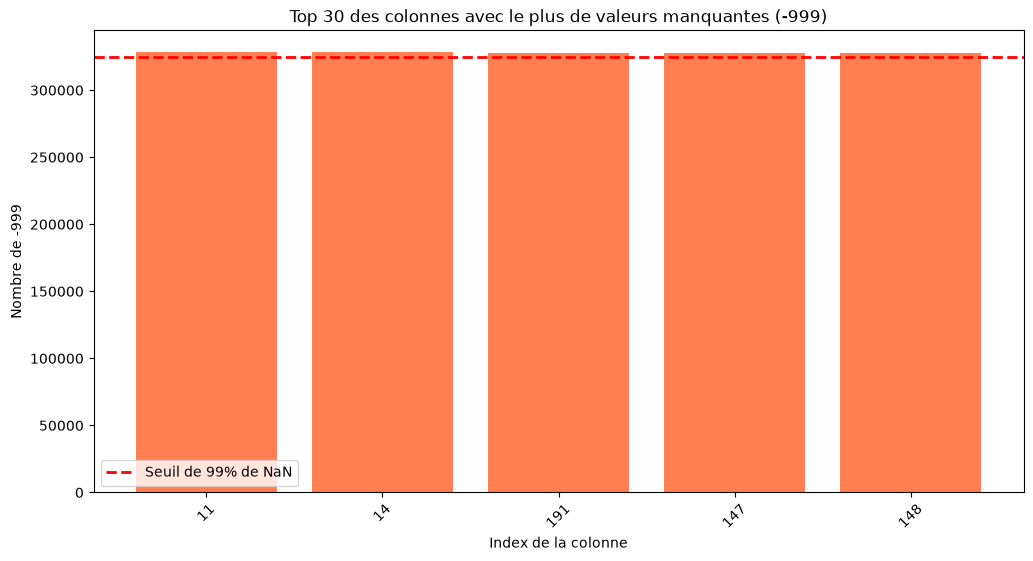

In [28]:
import sys
import numpy as np
sys.path.append("src")
import matplotlib.pyplot as plt
#from helpers import load_csv_data
from src.helpers import *            # load_csv_data, create_csv_submission
from src.implementations import *    # your 6 functions from Table 1

# 1. Charger les données avec la fonction officielle de votre groupe
DATA_PATH = "data/"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)
print("Données chargées :", x_train.shape)

# 2. PLOT : Compter les -999 par colonne (en pur Numpy !)
missing_counts = np.sum(np.isnan(x_train), axis=0)

# Filtrer pour ne garder que les colonnes qui ont des -999 et les trier
cols_with_missing = np.where(missing_counts > 0)[0]
counts = missing_counts[cols_with_missing]

# Tri décroissant
sort_indices = np.argsort(counts)[::-1]
top_counts = counts[sort_indices][:5] # On prend le top 30
top_cols = cols_with_missing[sort_indices][:5]

# 1. Calculer combien représentent 99% des lignes
seuil_99 = 0.99 * x_train.shape[0]



plt.figure(figsize=(12, 6))
plt.bar([str(c) for c in top_cols], top_counts, color='coral')
plt.title("Top 30 des colonnes avec le plus de valeurs manquantes (-999)")
plt.xlabel("Index de la colonne")
plt.ylabel("Nombre de -999")
plt.xticks(rotation=45)
# ligne horizontale en pointillé rouge qui montre les colonnes 99% de nan
plt.axhline(y=seuil_99, color='red', linestyle='--', linewidth=2, label='Seuil de 99% de NaN')
plt.legend()
plt.show()



Minimal preprcoessing 

In [37]:
#1. Calculer les NaN sur le set d'entraînement
missing_counts = np.sum(np.isnan(x_train), axis=0)
seuil_99 = 0.99 * x_train.shape[0]

# 2. Identifier les colonnes saines (moins de 99% de NaN)
colonnes_a_garder = np.where(missing_counts < seuil_99)[0]

# 3. Mettre à jour x_train et x_test avec uniquement ces colonnes
x_train = x_train[:, colonnes_a_garder]
x_test = x_test[:, colonnes_a_garder]

print(f"Nettoyage : {len(missing_counts) - len(colonnes_a_garder)} colonnes inutiles supprimées.")


# Replace missing values (NaN) by the column median computed on the TRAIN set
median = np.nan_to_num(np.nanmedian(x_train, axis=0))
x_train = np.where(np.isnan(x_train), median, x_train)
x_test = np.where(np.isnan(x_test), median, x_test)

# Standardize with train statistics
mean = x_train.mean(axis=0)
std = x_train.std(axis=0)
std[std == 0] = 1                     # avoid division by zero
x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

# Add the offset (bias) column -> tx, as in the labs
tx_train = np.c_[np.ones(x_train.shape[0]), x_train]
tx_test = np.c_[np.ones(x_test.shape[0]), x_test]

# Labels in {0,1} for logistic regression
y = (y_train + 1) / 2

Nettoyage : 30 colonnes inutiles supprimées.


In [38]:
initial_w = np.zeros(tx_tr.shape[1])
max_iters = 200
gamma = 0.1
lambda_ = 1e-4

w, loss = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
print("train loss:", loss)

train loss: 0.2430515051912906


In [39]:
def split_data(y, tx, ratio, seed=1):
    """Randomly split the data into train and validation sets."""
    np.random.seed(seed)
    idx = np.random.permutation(len(y))
    cut = int(ratio * len(y))
    return tx[idx[:cut]], y[idx[:cut]], tx[idx[cut:]], y[idx[cut:]]

tx_tr, y_tr, tx_val, y_val = split_data(y, tx_train, ratio=0.8)

def sigmoid(t):
    return 1.0 / (1.0 + np.exp(-t))

def predict_labels(w, tx, threshold=0.15):
    """Return predictions in {-1, 1} (format required by the submission)."""
    return np.where(sigmoid(tx @ w) >= threshold, 1, -1)

def f1_score(y_true, y_pred):
    """F1 score for labels in {-1, 1}."""
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == -1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == -1))
    return 2 * tp / (2 * tp + fp + fn + 1e-12)

y_val_pm = 2 * y_val - 1             # back to {-1, 1}
y_pred_val = predict_labels(w, tx_val)
print("accuracy:", np.mean(y_pred_val == y_val_pm))
print("F1 score:", f1_score(y_val_pm, y_pred_val))

accuracy: 0.7611044234842367
F1 score: 0.35814296241709653


In [40]:
DATA_PATH = "data/"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)

# 1. Définir le seuil et compter les NaN
seuil_99 = 0.99 * x_train.shape[0]
missing_counts = np.sum(np.isnan(x_train), axis=0)

# 2. Trouver les colonnes à garder (celles qui ont strictement moins de 99% de NaN)
colonnes_a_garder = np.where(missing_counts < seuil_99)[0]
nb_supprimees = x_train.shape[1] - len(colonnes_a_garder)
print(f"On a supprimé {nb_supprimees} colonnes inutiles !")

# 3. Filtrer les données d'entraînement
x_train_filtre = x_train[:, colonnes_a_garder]

# ==========================================
# REPRODUCTION DU PIPELINE DE TON GROUPE
# ==========================================

# Remplacer les NaN restants par la médiane de chaque colonne filtrée
median = np.nanmedian(x_train_filtre, axis=0)
x_train_imputed = np.where(np.isnan(x_train_filtre), median, x_train_filtre)

# Standardisation
mean_x = np.mean(x_train_imputed, axis=0)
std_x = np.std(x_train_imputed, axis=0)
std_x[std_x == 0] = 1 # Eviter la division par 0
tx_train_std = (x_train_imputed - mean_x) / std_x

# Ajouter la colonne de biais (des 1)
tx_train_final = np.c_[np.ones(tx_train_std.shape[0]), tx_train_std]

# Labels pour la régression logistique (de {-1, 1} vers {0, 1})
y = (y_train + 1) / 2

# Split Train/Validation (Assure-toi que la fonction split_data est bien chargée)
tx_tr, y_tr, tx_val, y_val = split_data(y, tx_train_final, ratio=0.8)

# Paramètres d'entraînement du groupe
initial_w = np.zeros(tx_tr.shape[1])
max_iters = 200
gamma = 0.1
lambda_ = 1e-4

# Entraînement 
w, loss = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
print("Train loss:", loss)

# Évaluation sur le set de validation
y_val_pm = 2 * y_val - 1 # Retour aux labels originaux {-1, 1}
y_pred_val = predict_labels(w, tx_val)

print("Ancien F1 score : 0.1316")
print("NOUVEAU F1 score :", f1_score(y_val_pm, y_pred_val))

On a supprimé 30 colonnes inutiles !
Train loss: 0.2430515051912906
Ancien F1 score : 0.1316
NOUVEAU F1 score : 0.35814296241709653
